In [2]:
import sys, nibabel, nilearn
print(sys.executable)
print(nibabel.__version__, nilearn.__version__)


/ptmp/ipirpiroglu/bids_data/env/bin/python
5.4.2 0.14.0


In [3]:
import inspect
from nilearn import image, masking, plotting

for f in (image.mean_img, masking.compute_epi_mask, plotting.plot_carpet):
    print(f.__name__, inspect.signature(f))
    print()

Matplotlib is building the font cache; this may take a moment.


mean_img (imgs, target_affine=None, target_shape=None, verbose=0, n_jobs=1, copy_header=True) -> nibabel.nifti1.Nifti1Image | nilearn.surface.surface.SurfaceImage

compute_epi_mask (epi_img, lower_cutoff=0.2, upper_cutoff=0.85, connected=True, opening=2, exclude_zeros=False, ensure_finite=True, target_affine=None, target_shape=None, memory=None, verbose=0) -> nibabel.nifti1.Nifti1Image

plot_carpet (img, mask_img=None, mask_labels=None, t_r=None, detrend: bool = True, output_file: str | pathlib.Path | None = None, figure=None, axes=None, vmin=None, vmax=None, title: str | None = None, cmap='gray', cmap_labels='gist_ncar', standardize=True)



(162, 200, 36) (162, 200, 36)


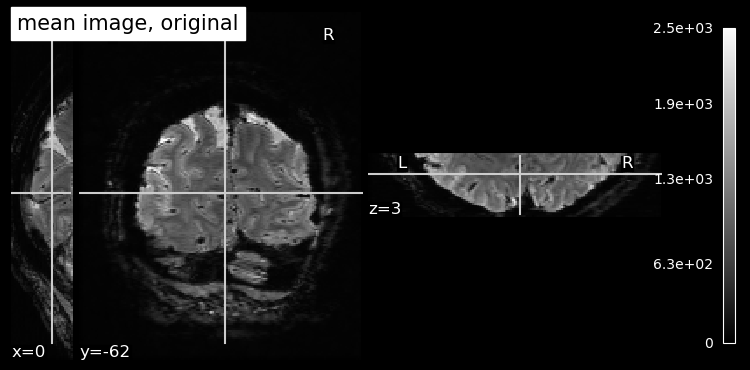

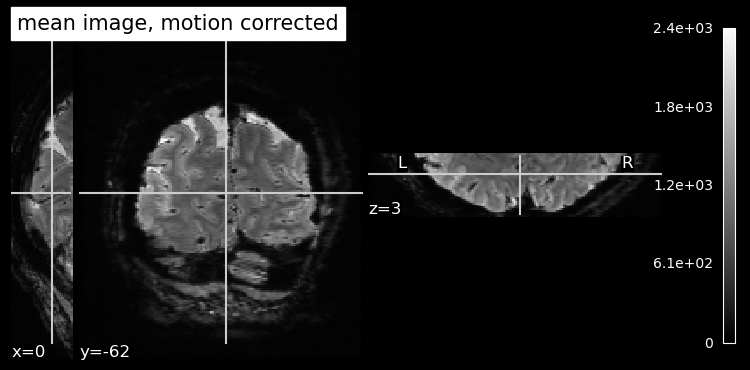

In [4]:
from pathlib import Path
from nilearn.image import mean_img
from nilearn.plotting import plot_epi, show

BIDS = Path("/ptmp/ipirpiroglu/ipirpiroglu/data/sample_bids")
RUN = "sub-01_ses-1_task-exp1_run-01"
raw_file = BIDS / "sub-01/ses-1/func" / f"{RUN}_bold.nii"
mc_file = BIDS / "derivatives/motion_correction/sub-01/ses-1/func" / f"{RUN}_desc-mc_bold.nii.gz"

mean_raw = mean_img(str(raw_file))
mean_mc = mean_img(str(mc_file))
print(mean_raw.shape, mean_mc.shape)

plot_epi(mean_raw, title="mean image, original")
plot_epi(mean_mc, title="mean image, motion corrected")
show()

In [1]:
1+1




2

mask shape: (162, 200, 36)  voxels in mask: 157554


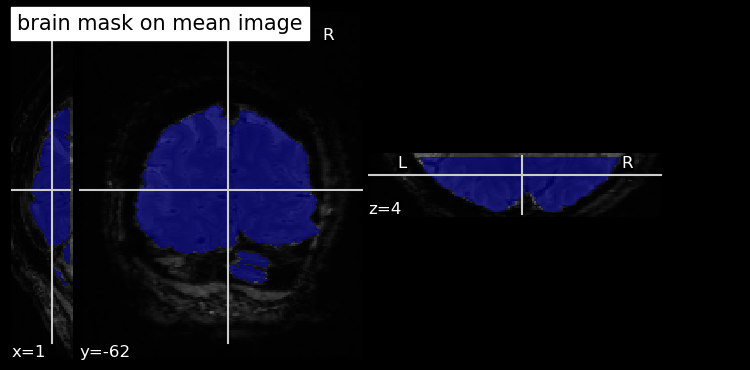

In [5]:
from nilearn.masking import compute_epi_mask
from nilearn.plotting import plot_roi

mask_mc = compute_epi_mask(mean_mc)
print("mask shape:", mask_mc.shape, " voxels in mask:", int(mask_mc.get_fdata().sum()))
plot_roi(mask_mc, bg_img=mean_mc, title="brain mask on mean image")
show()

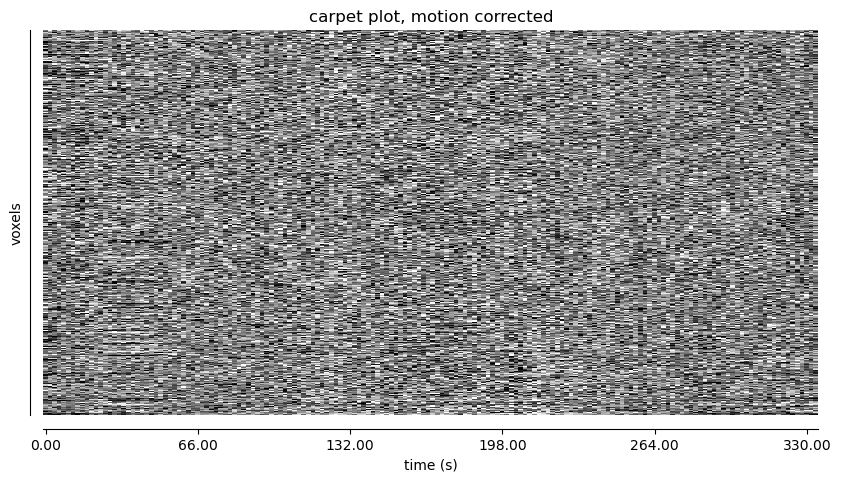

In [6]:
from nilearn.plotting import plot_carpet

plot_carpet(
    str(mc_file),
    mask_img=mask_mc,
    t_r=2.0,
    standardize="zscore_sample",
    title="carpet plot, motion corrected",
)
show()

In [7]:
import numpy as np

par = np.loadtxt(BIDS / "derivatives/motion_correction/sub-01/ses-1/func" / f"{RUN}_desc-mc_bold.par")
step = np.abs(np.diff(par, axis=0))
fd = step[:, 3:6].sum(axis=1) + 50.0 * step[:, 0:3].sum(axis=1)   # mm, 50 mm küre üzerindeki dönmeler
for i in np.argsort(fd)[::-1][:5]:
    print(f"volume {i+1}: jump of {fd[i]:.3f} mm (time {(i+1)*2:.0f} s)")
print("mean framewise displacement (mm):", round(fd.mean(), 4))

volume 94: jump of 0.363 mm (time 188 s)
volume 92: jump of 0.334 mm (time 184 s)
volume 98: jump of 0.318 mm (time 196 s)
volume 95: jump of 0.312 mm (time 190 s)
volume 64: jump of 0.312 mm (time 128 s)
mean framewise displacement (mm): 0.1392
